In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, precision_score,
                              recall_score, f1_score)
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "#0f1117",
    "axes.facecolor":   "#1a1d27",
    "axes.edgecolor":   "#3a3f55",
    "axes.labelcolor":  "#c8cce0",
    "xtick.color":      "#8890aa",
    "ytick.color":      "#8890aa",
    "text.color":       "#dde1f0",
    "grid.color":       "#2a2f45",
    "grid.linestyle":   "--",
    "grid.alpha":       0.5,
    "figure.titlesize": 14,
    "axes.titlesize":   11,
    "axes.titleweight": "bold",
    "axes.labelsize":   9,
    "legend.fontsize":  8,
    "legend.framealpha": 0.2,
    "legend.edgecolor": "#3a3f55",
})

#custom colours as variables
BLUE   = "#4f9de8"
ORANGE = "#f0864a"
GREEN  = "#3ecf8e"
RED    = "#e05252"
PURPLE = "#a78bfa"
GOLD   = "#f5c842"
GREY   = "#5a6080"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('data/energydata_complete.csv', parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"  Lignes : {df.shape[0]:,}   |   Colonnes : {df.shape[1]}")
print(f"  Période : {df['date'].min().date()} → {df['date'].max().date()}")
print(f"  Cible 'Appliances' — min={df['Appliances'].min()} Wh  "
      f"max={df['Appliances'].max()} Wh  "
      f"moy={df['Appliances'].mean():.1f} Wh")



  Lignes : 19,735   |   Colonnes : 29
  Période : 2016-01-11 → 2016-05-27
  Cible 'Appliances' — min=10 Wh  max=1080 Wh  moy=97.7 Wh


Section 1a - Série temporelle

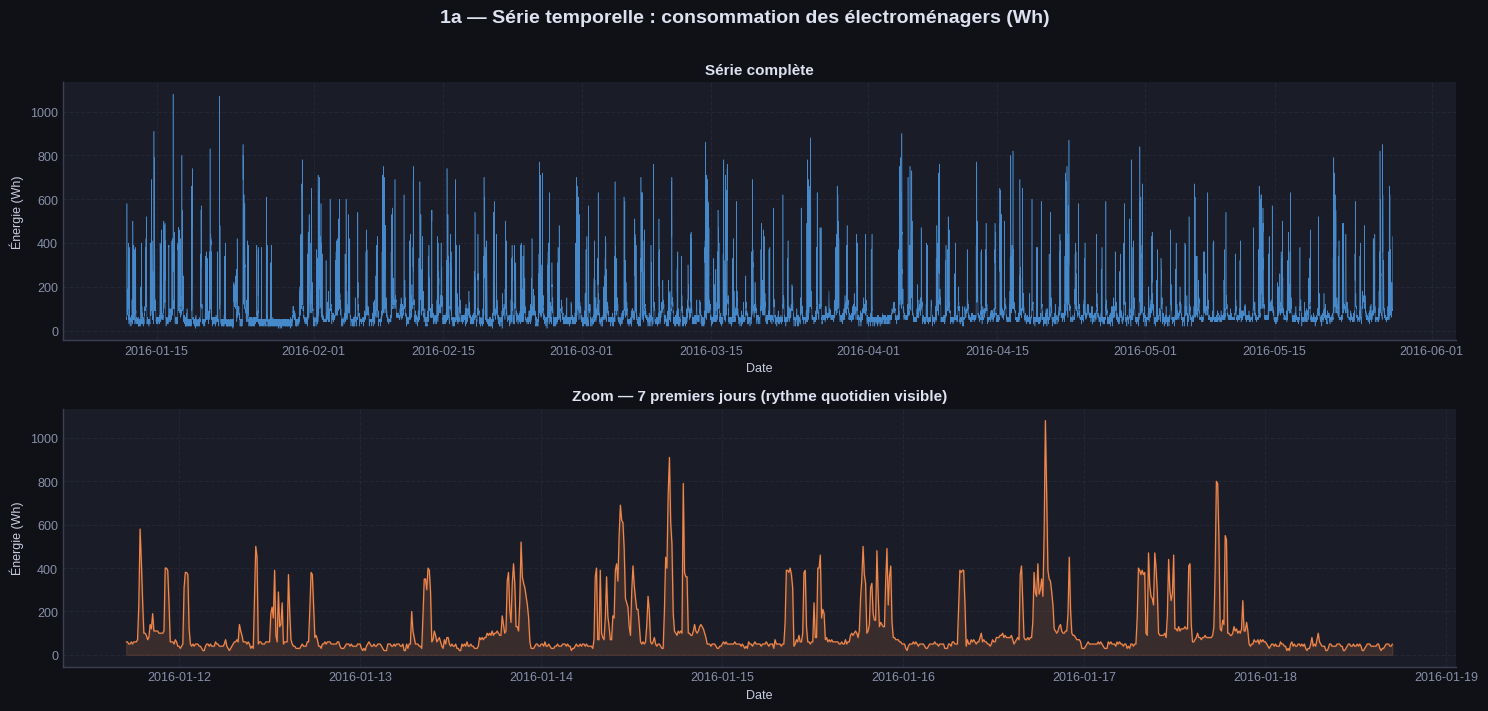

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), facecolor="#0f1117")
fig.suptitle("1a — Série temporelle : consommation des électroménagers (Wh)",
             fontweight="bold", color="#dde1f0", y=1.01)

axes[0].plot(df["date"], df["Appliances"],
             color=BLUE, linewidth=0.4, alpha=0.85)
axes[0].set_title("Série complète")
axes[0].set_ylabel("Énergie (Wh)")
axes[0].set_xlabel("Date")

week = df.iloc[:1008]
axes[1].plot(week["date"], week["Appliances"],
             color=ORANGE, linewidth=0.9)
axes[1].fill_between(week["date"], week["Appliances"],
                     alpha=0.15, color=ORANGE)
axes[1].set_title("Zoom — 7 premiers jours (rythme quotidien visible)")
axes[1].set_ylabel("Énergie (Wh)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

Visualisation de la consommation d'énergie des appareils électroménagers (Wh) sur la période du 11 janvier 2016 au 27 mai 2016. Deux graphiques sont présentés : la série complète et un zoom sur 7 jours montrant le rythme quotidien.

Section 1b - Distribution



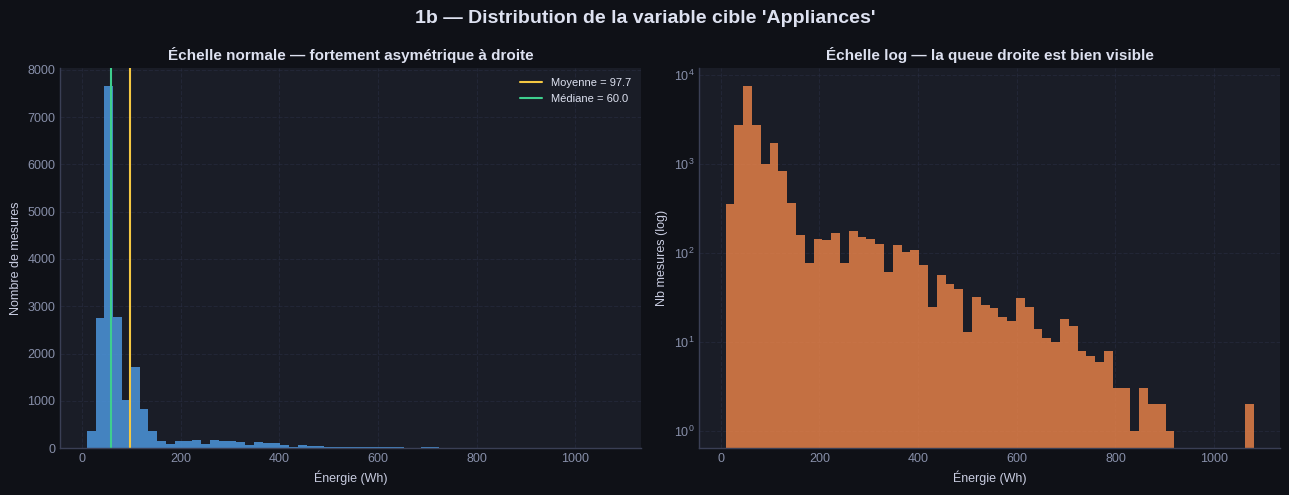

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="#0f1117")
fig.suptitle("1b — Distribution de la variable cible 'Appliances'",
             fontweight="bold", color="#dde1f0")

axes[0].hist(df["Appliances"], bins=60, color=BLUE,
             edgecolor="none", alpha=0.8)
axes[0].set_title("Échelle normale — fortement asymétrique à droite")
axes[0].set_xlabel("Énergie (Wh)")
axes[0].set_ylabel("Nombre de mesures")
axes[0].axvline(df["Appliances"].mean(), color=GOLD, lw=1.5,
                label=f"Moyenne = {df['Appliances'].mean():.1f}")
axes[0].axvline(df["Appliances"].median(), color=GREEN, lw=1.5,
                label=f"Médiane = {df['Appliances'].median():.1f}")
axes[0].legend()

axes[1].hist(df["Appliances"], bins=60, log=True,
             color=ORANGE, edgecolor="none", alpha=0.8)
axes[1].set_title("Échelle log — la queue droite est bien visible")
axes[1].set_xlabel("Énergie (Wh)")
axes[1].set_ylabel("Nb mesures (log)")

plt.tight_layout()
plt.show()

Histogrammes de la variable cible "Appliances" montrant une distribution fortement asymétrique à droite. Deux échelles sont utilisées : normale et logarithmique.

Section 1c - Température & Humidité

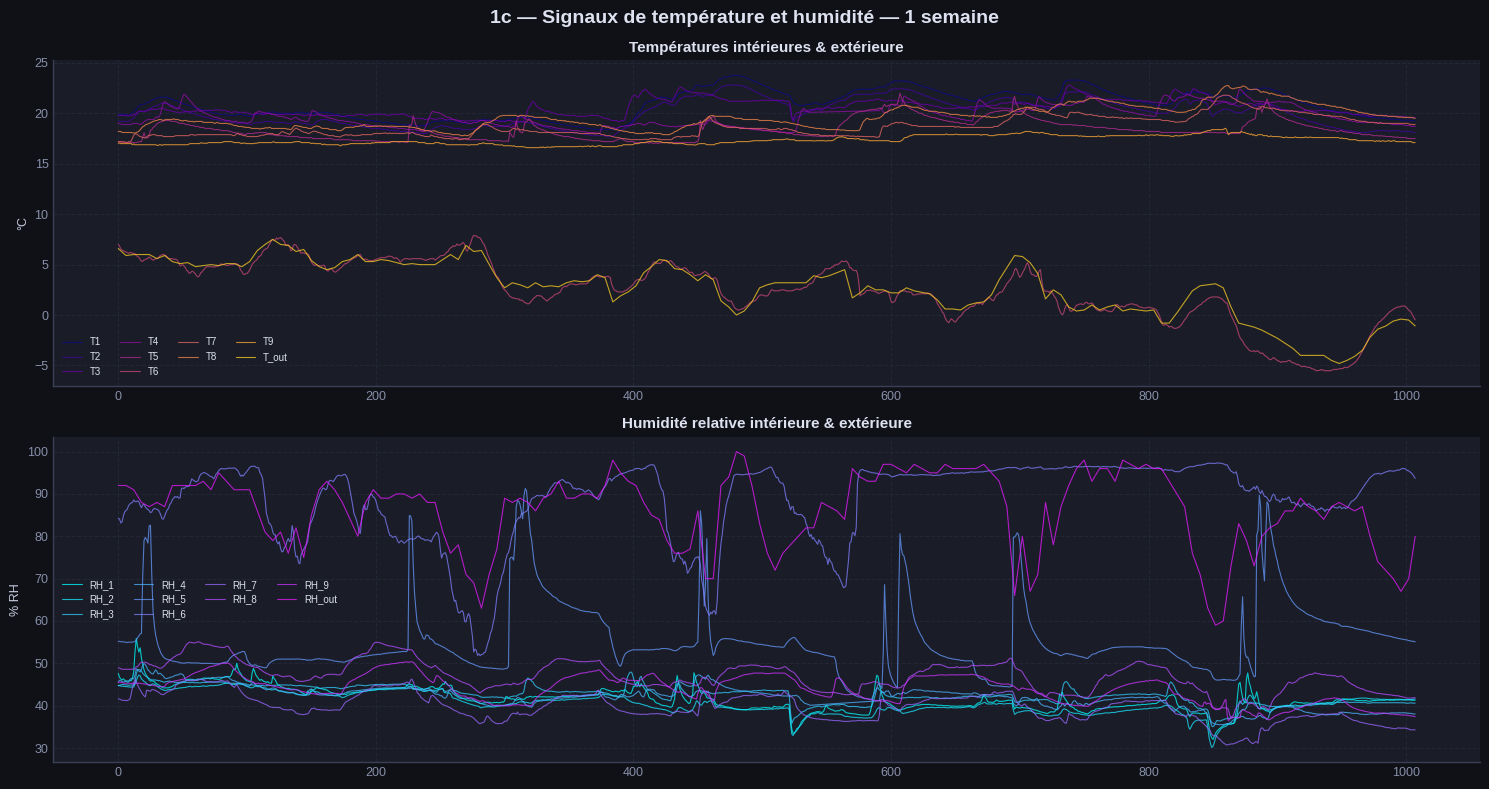

In [ ]:
temp_cols = [c for c in df.columns if c.startswith("T") and c != "Tdewpoint"]
rh_cols   = [c for c in df.columns if c.startswith("RH_")]

fig, axes = plt.subplots(2, 1, figsize=(15, 8), facecolor="#0f1117")
fig.suptitle("1c — Signaux de température et humidité — 1 semaine",
             fontweight="bold", color="#dde1f0")

cmap_t = plt.cm.plasma
for k, col in enumerate(temp_cols):
    axes[0].plot(df[col].iloc[:1008], linewidth=0.8, alpha=0.75,
                 color=cmap_t(k / len(temp_cols)), label=col)
axes[0].set_title("Températures intérieures & extérieure")
axes[0].set_ylabel("°C")
axes[0].legend(ncol=4, fontsize=7)

cmap_rh = plt.cm.cool
for k, col in enumerate(rh_cols):
    axes[1].plot(df[col].iloc[:1008], linewidth=0.8, alpha=0.75,
                 color=cmap_rh(k / len(rh_cols)), label=col)
axes[1].set_title("Humidité relative intérieure & extérieure")
axes[1].set_ylabel("% RH")
axes[1].legend(ncol=4, fontsize=7)

plt.tight_layout()
plt.show()

Visualisation des signaux de température (intérieurs et extérieurs) et d'humidité relative sur une période d'une semaine.

Section 1d - Matrice de corrélation

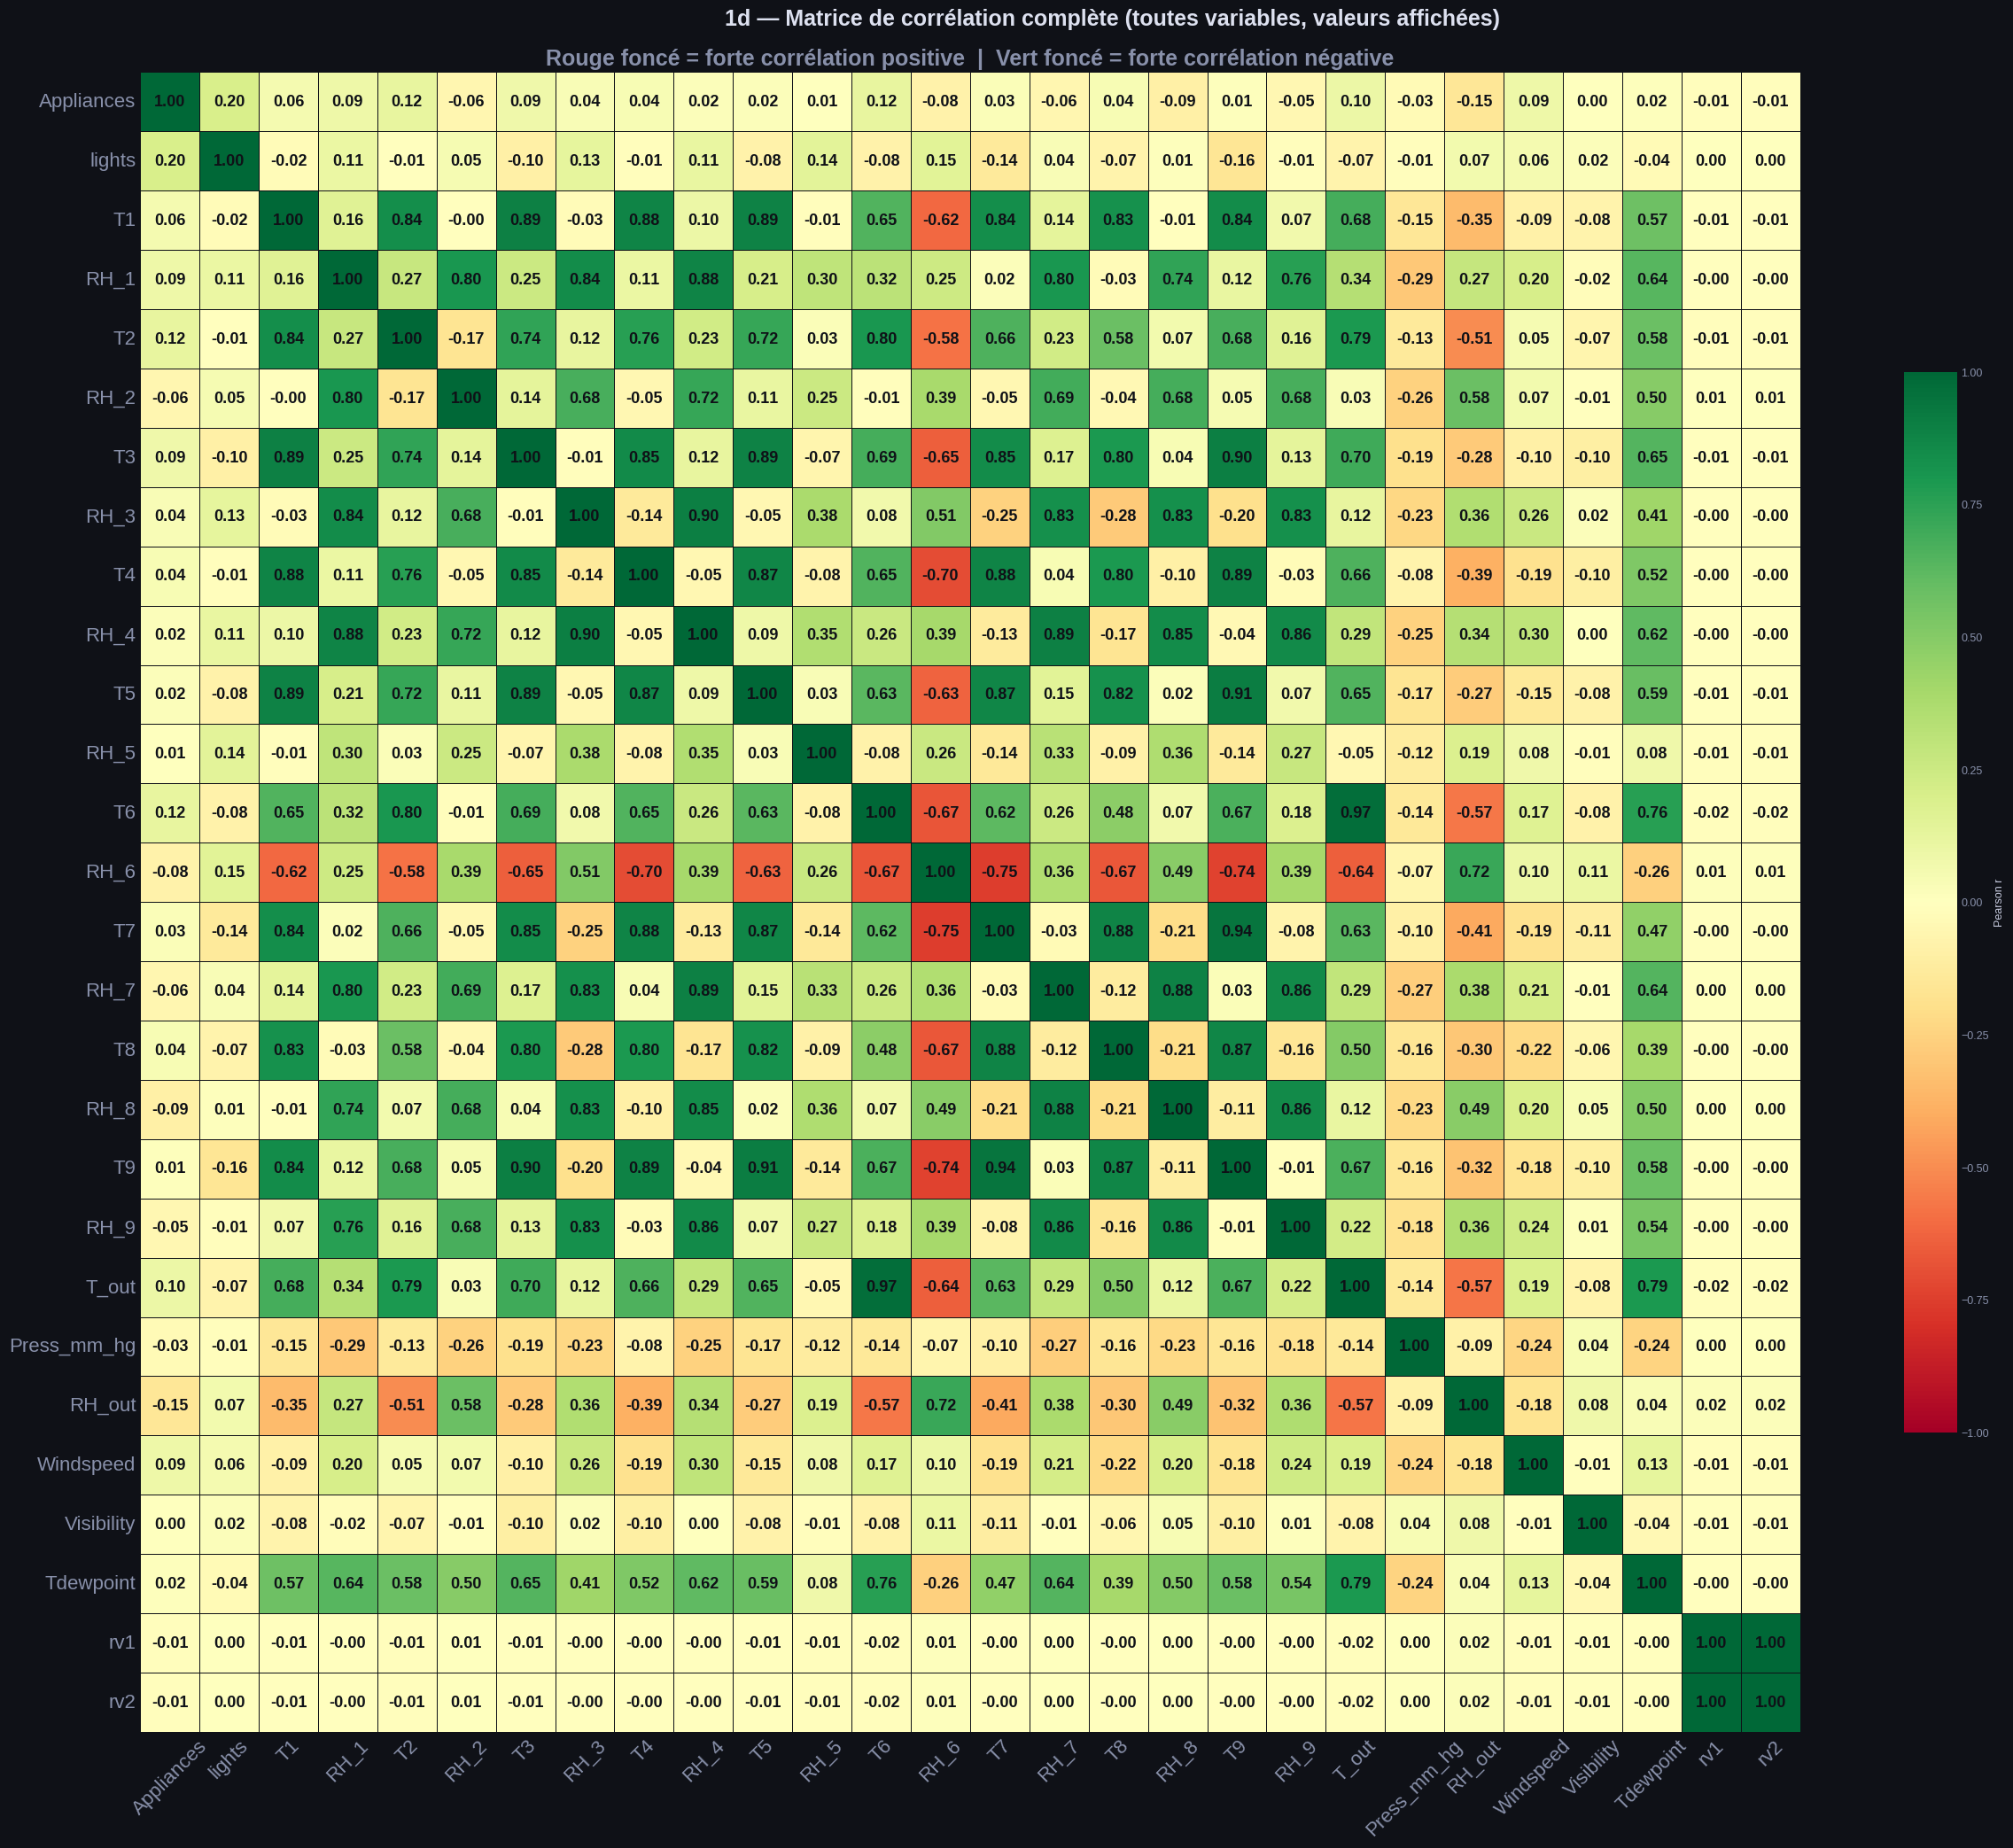

In [ ]:
df_num = df.drop(columns=["date"])
corr   = df_num.corr()

n_vars = corr.shape[0]
# Increase figure size and annotation font
fig_size = max(20, n_vars * 0.9)
annot_fs = 13

fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85), facecolor="#0f1117")
fig.suptitle("1d — Matrice de corrélation complète (toutes variables, valeurs affichées)",
             fontweight="bold", color="#dde1f0", fontsize=18)

sns.heatmap(
    corr, ax=ax,
    cmap="RdYlGn",
    center=0, vmin=-1, vmax=1,
    linewidths=0.4, linecolor="#0f1117",
    annot=True,
    fmt=".2f",
    annot_kws={"size": annot_fs, "color": "#0f1117", "weight": "bold"},
    cbar_kws={"label": "Pearson r", "shrink": 0.6},
    square=True,
)
ax.set_title(
    "Rouge foncé = forte corrélation positive  |  Vert foncé = forte corrélation négative",
    fontsize=18, color="#8890aa"
)
ax.tick_params(axis="x", rotation=45, labelsize=16)
ax.tick_params(axis="y", rotation=0,  labelsize=16)

plt.tight_layout()
plt.savefig("1d_heatmap.png", dpi=150, bbox_inches="tight",
            facecolor="#0f1117")
plt.show()

Section 1e - Corrélations avec la cible

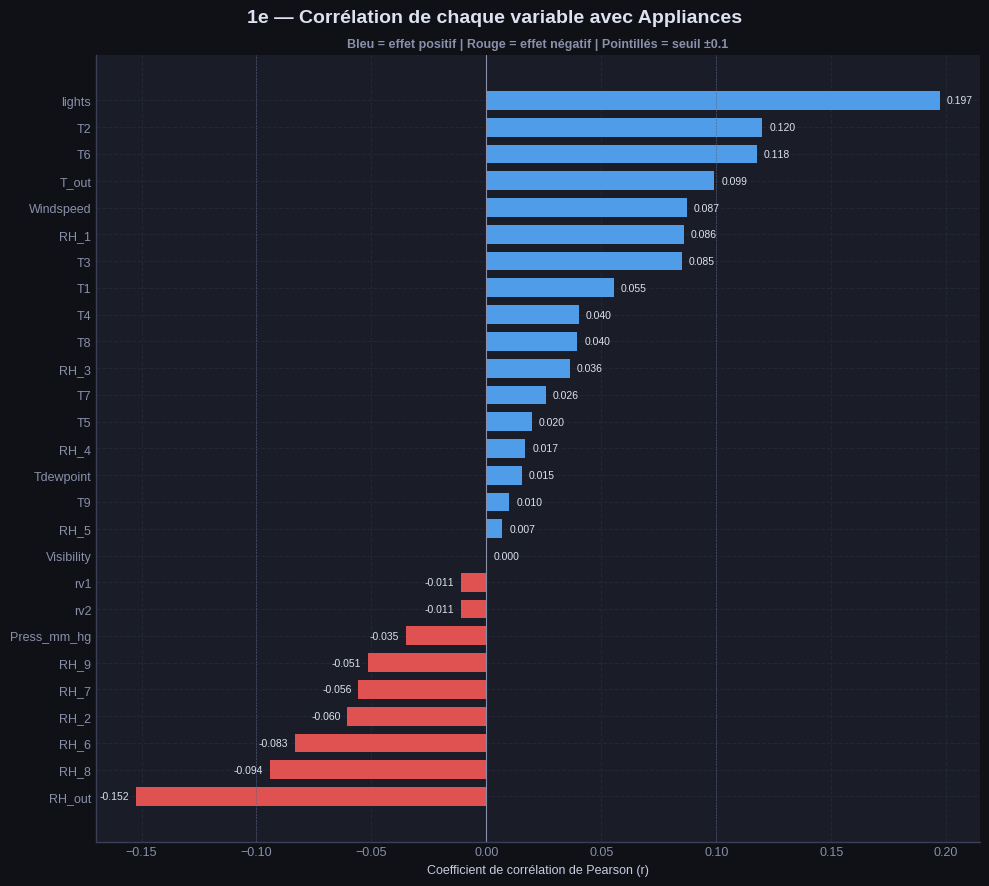

In [ ]:
corr_target = corr["Appliances"].drop("Appliances").sort_values()
bar_colors  = [RED if v < 0 else BLUE for v in corr_target.values]

fig, ax = plt.subplots(figsize=(10, 9), facecolor="#0f1117")
fig.suptitle("1e — Corrélation de chaque variable avec Appliances",
             fontweight="bold", color="#dde1f0")
bars = ax.barh(corr_target.index, corr_target.values,
               color=bar_colors, edgecolor="none", height=0.7)
ax.axvline(0, color="#8890aa", lw=0.8)
ax.axvline( 0.1, color=GREY, lw=0.4, linestyle="--")
ax.axvline(-0.1, color=GREY, lw=0.4, linestyle="--")
for bar, val in zip(bars, corr_target.values):
    ax.text(val + (0.003 if val >= 0 else -0.003),
            bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center",
            ha="left" if val >= 0 else "right", fontsize=7.5,
            color="#dde1f0")
ax.set_xlabel("Coefficient de corrélation de Pearson (r)")
ax.set_title("Bleu = effet positif | Rouge = effet négatif | "
             "Pointillés = seuil ±0.1", fontsize=9, color="#8890aa")
plt.tight_layout()
plt.show()

 Section 1f - Nuages ​​de points

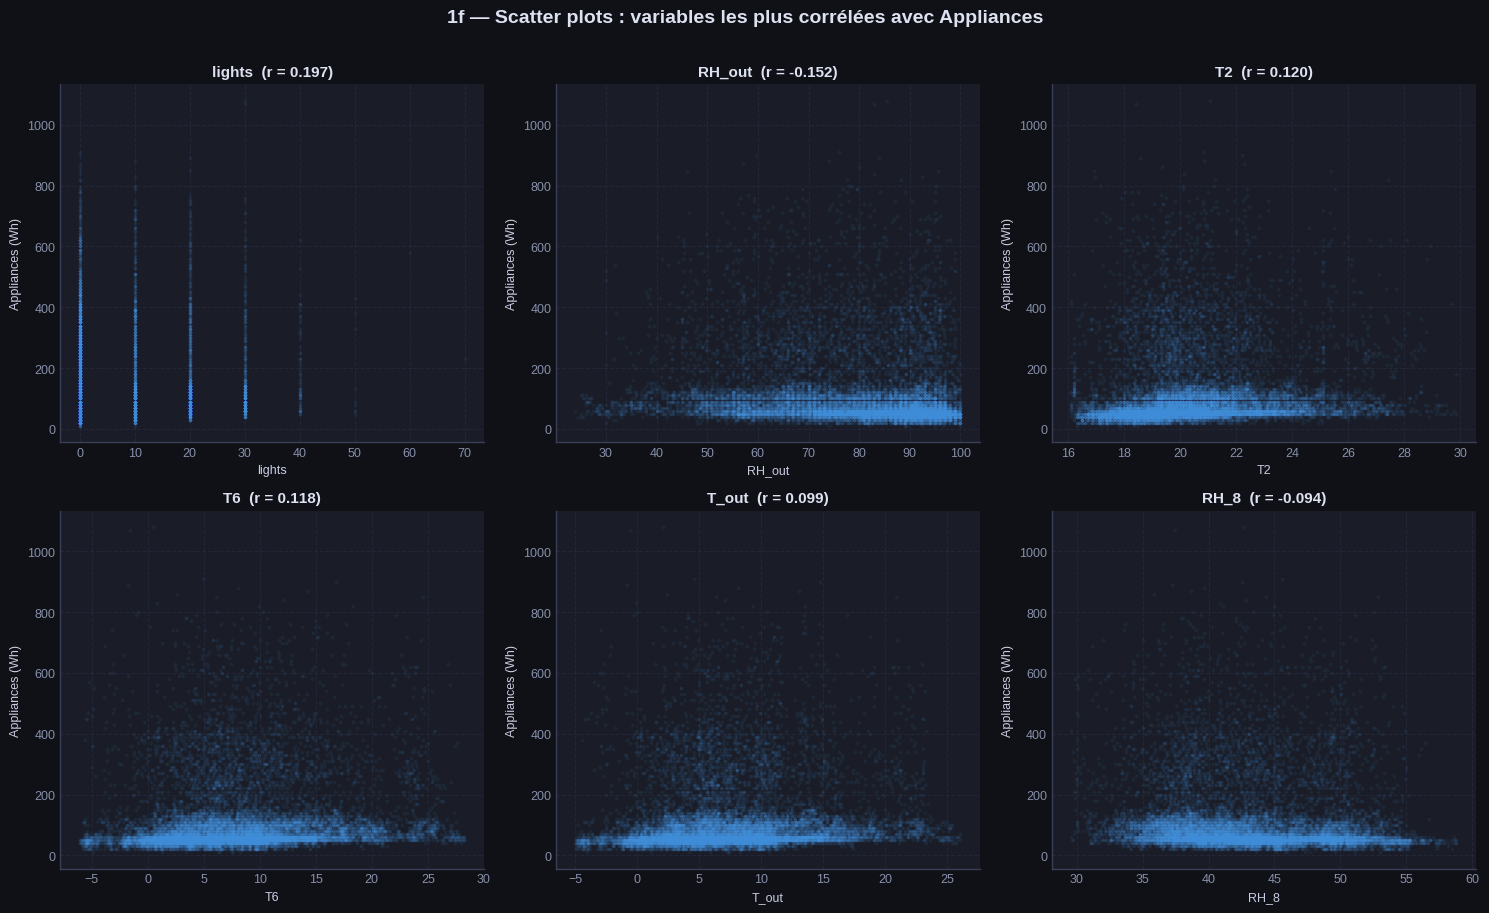

In [ ]:
top6 = corr_target.abs().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 9), facecolor="#0f1117")
fig.suptitle("1f —Nuages des points : variables les plus corrélées avec Appliances",
             fontweight="bold", color="#dde1f0", y=1.01)
axes = axes.flatten()
for i, var in enumerate(top6):
    axes[i].scatter(df[var], df["Appliances"],
                    alpha=0.06, s=3, color=BLUE)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Appliances (Wh)")
    r = corr_target.get(var, corr["Appliances"].get(var, 0))
    axes[i].set_title(f"{var}  (r = {r:.3f})")
plt.tight_layout()
plt.show()

Découpage chronologique Train / Test

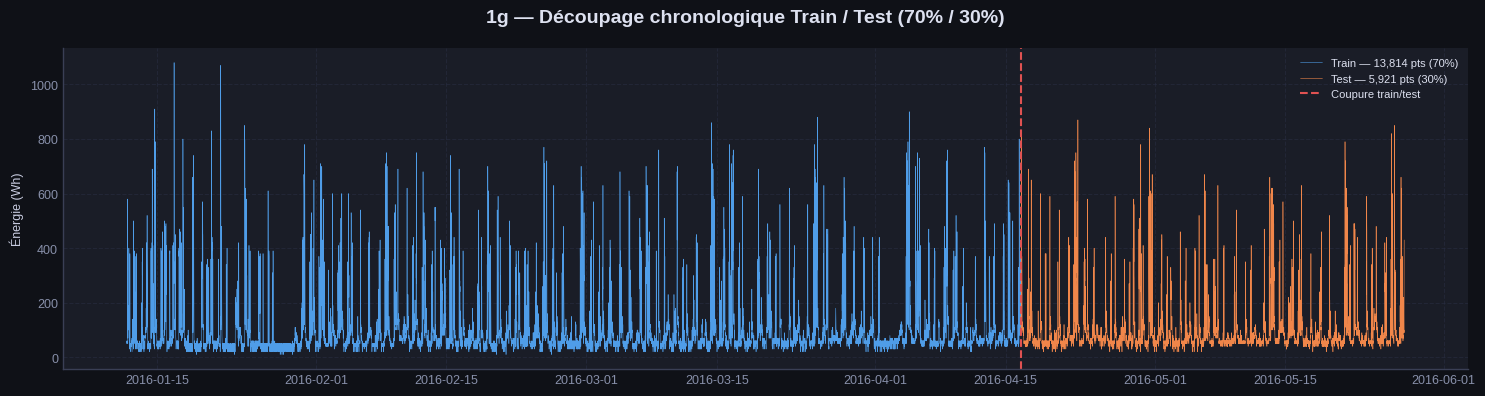


  Train : 13,814 exemples × 27 variables
  Test  : 5,921 exemples × 27 variables


In [ ]:
TRAIN_RATIO = 0.70
feature_names = [c for c in df_num.columns if c != "Appliances"]

X_all = df_num[feature_names].values
y_all = df_num["Appliances"].values

n_train = int(TRAIN_RATIO * len(X_all))
X_train_raw, X_test_raw = X_all[:n_train], X_all[n_train:]
y_train, y_test         = y_all[:n_train], y_all[n_train:]

# Normalisation : µ et σ calculés UNIQUEMENT sur le train
X_mean = X_train_raw.mean(axis=0)
X_std  = X_train_raw.std(axis=0)
X_std[X_std == 0] = 1.0

X_train = (X_train_raw - X_mean) / X_std
X_test  = (X_test_raw  - X_mean) / X_std

# Ajout du biais
X_train_b = np.c_[np.ones(len(X_train)), X_train]
X_test_b  = np.c_[np.ones(len(X_test)),  X_test]

# Visualisation du découpage
fig, ax = plt.subplots(figsize=(15, 4), facecolor="#0f1117")
fig.suptitle("1g — Découpage chronologique Train / Test (70% / 30%)",
             fontweight="bold", color="#dde1f0")
ax.plot(df["date"].iloc[:n_train], y_train,
        color=BLUE, lw=0.4, label=f"Train — {n_train:,} pts (70%)")
ax.plot(df["date"].iloc[n_train:], y_test,
        color=ORANGE, lw=0.4, label=f"Test — {len(y_test):,} pts (30%)")
ax.axvline(df["date"].iloc[n_train], color=RED, lw=1.5,
           linestyle="--", label="Coupure train/test")
ax.set_ylabel("Énergie (Wh)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"\n  Train : {X_train.shape[0]:,} exemples × {X_train.shape[1]} variables")
print(f"  Test  : {X_test.shape[0]:,} exemples × {X_test.shape[1]} variables")

Cost curve visualization


  [GD α=0.01, 3000 itérations]
  Coût initial  : 10587.09
  Coût final    : 4739.18
  Coût analytique (référence) : 4727.93
  Écart relatif GD/analytique : 0.24%


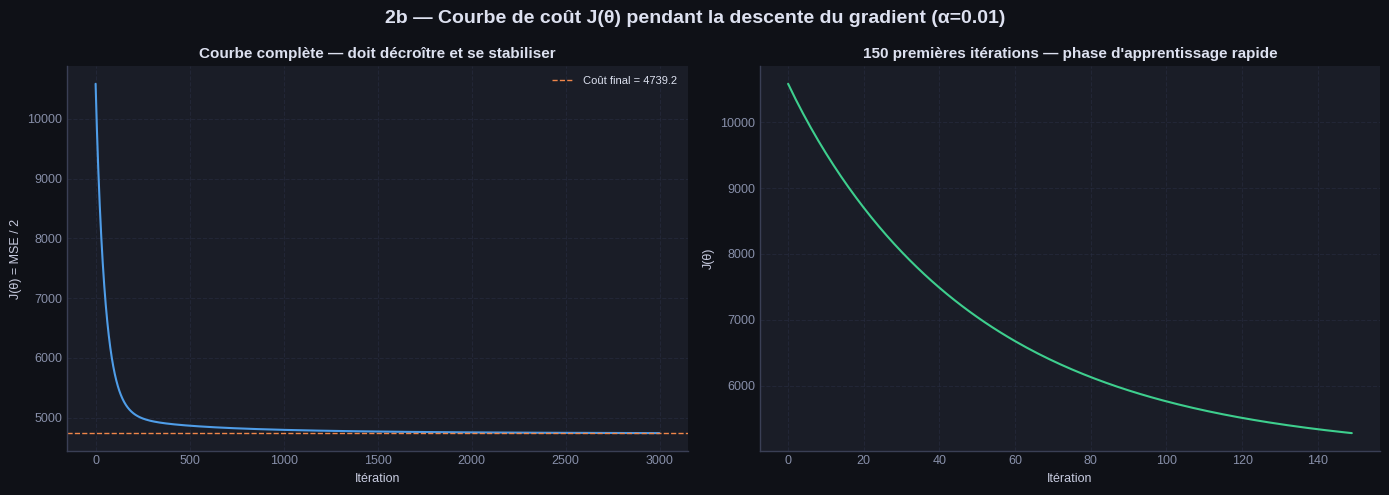


  [2c] Comparaison des pas d'apprentissage :
    α=0.0001  coût final = 10242.7
    α=0.001   coût final = 8047.3
    α=0.01    coût final = 4940.3
    α=0.1     coût final = 4739.2
    α=0.8     coût final = 14244701193320.1


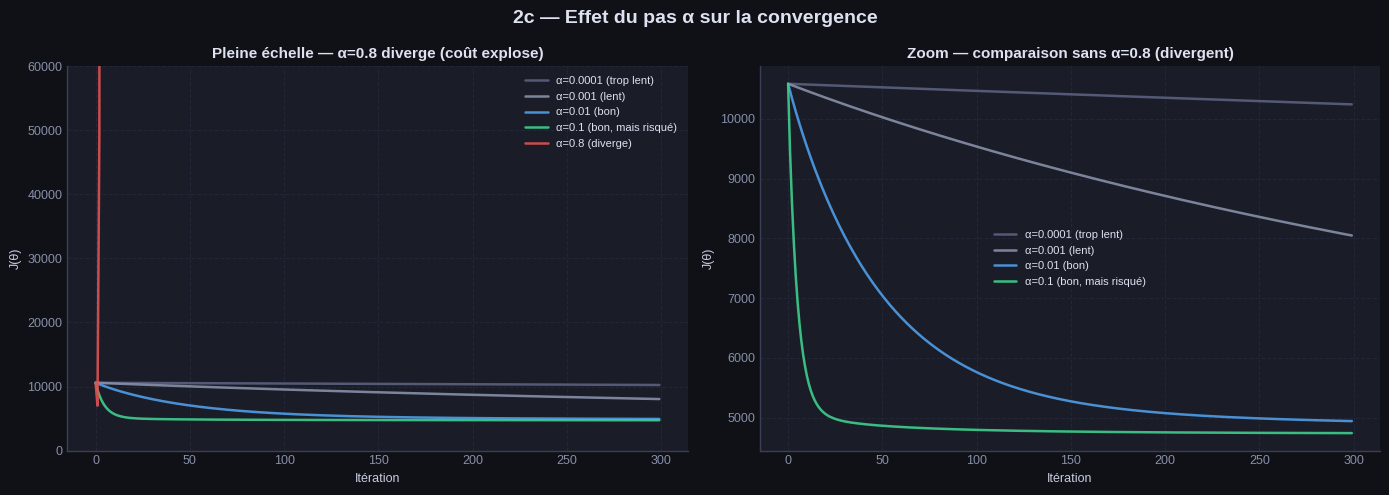


  CONCLUSION 2c :
    α trop petit (0.0001) → descente très lente, loin de converger en 300 itérations
    α=0.001 → convergence stable mais lente
    α=0.01  → convergence stable et régulière : meilleur compromis vitesse/robustesse ✓
    α=0.1   → converge plus vite mais moins robuste selon les données
    α=0.8   → diverge : le pas dépasse le minimum, le coût explose


In [ ]:
def gradient_descent(X_b, y, alpha=0.01, n_iter=500):
    m, n      = X_b.shape
    theta     = np.zeros(n)
    cost_hist = []
    for _ in range(n_iter):
        error = X_b @ theta - y
        cost  = (error ** 2).sum() / (2 * m)
        cost_hist.append(cost)
        theta = theta - alpha / m * (X_b.T @ error)
        if np.isnan(cost) or cost > 1e13:
            cost_hist += [float("nan")] * (n_iter - len(cost_hist))
            break
    return theta, cost_hist

ALPHA_GOOD = 0.01
N_ITER     = 3000

theta_gd, cost_hist = gradient_descent(X_train_b, y_train,
                                        alpha=ALPHA_GOOD, n_iter=N_ITER)
print(f"\n  [GD α={ALPHA_GOOD}, {N_ITER} itérations]")
print(f"  Coût initial  : {cost_hist[0]:.2f}")
print(f"  Coût final    : {cost_hist[-1]:.2f}")

# Analytical reference cost for convergence check
theta_an_tmp = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train
cost_an = ((X_train_b @ theta_an_tmp - y_train)**2).sum() / (2*len(y_train))
print(f"  Coût analytique (référence) : {cost_an:.2f}")
print(f"  Écart relatif GD/analytique : {abs(cost_hist[-1]-cost_an)/cost_an*100:.2f}%")

# Courbe de coût
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor="#0f1117")
fig.suptitle(f"2b — Courbe de coût J(θ) pendant la descente du gradient (α={ALPHA_GOOD})",
             fontweight="bold", color="#dde1f0")

axes[0].plot(cost_hist, color=BLUE, lw=1.5)
axes[0].axhline(cost_hist[-1], color=ORANGE, lw=1, linestyle="--",
                label=f"Coût final = {cost_hist[-1]:.1f}")
axes[0].set_title("Courbe complète — doit décroître et se stabiliser")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("J(θ) = MSE / 2")
axes[0].legend()

axes[1].plot(cost_hist[:min(150, len(cost_hist))], color=GREEN, lw=1.5)
axes[1].set_title("150 premières itérations — phase d'apprentissage rapide")
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("J(θ)")

plt.tight_layout()
plt.savefig("2b_cout_gradient.png", dpi=150, bbox_inches="tight",
            facecolor="#0f1117")
plt.show()

# Effet du pas d'apprentissage
alphas_test  = [0.0001, 0.001, 0.01, 0.1, 0.8]
labels_alpha = ["α=0.0001 (trop lent)", "α=0.001 (lent)",
                "α=0.01 (bon)", "α=0.1 (bon, mais risqué)",
                "α=0.8 (diverge)"]
colors_alpha = [GREY, "#8890aa", BLUE, GREEN, RED]

print("\n  [2c] Comparaison des pas d'apprentissage :")
all_costs = {}
for a in alphas_test:
    _, ch = gradient_descent(X_train_b, y_train, alpha=a, n_iter=300)
    all_costs[a] = ch
    last_valid = [c for c in ch if not np.isnan(c)]
    status = f"{last_valid[-1]:.1f}" if last_valid else "DIVERGE"
    print(f"    α={a:<6}  coût final = {status}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor="#0f1117")
fig.suptitle("2c — Effet du pas α sur la convergence",
             fontweight="bold", color="#dde1f0")

for a, lbl, col in zip(alphas_test, labels_alpha, colors_alpha):
    axes[0].plot(all_costs[a], color=col, lw=1.8, label=lbl, alpha=0.9)
axes[0].set_ylim(0, 60000)
axes[0].set_title("Pleine échelle — α=0.8 diverge (coût explose)")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("J(θ)")
axes[0].legend()

for a, lbl, col in zip(alphas_test[:-1], labels_alpha[:-1], colors_alpha[:-1]):
    axes[1].plot(all_costs[a], color=col, lw=1.8, label=lbl, alpha=0.9)
axes[1].set_title("Zoom — comparaison sans α=0.8 (divergent)")
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("J(θ)")
axes[1].legend()

plt.tight_layout()
plt.savefig("2c_effet_alpha.png", dpi=150, bbox_inches="tight",
            facecolor="#0f1117")
plt.show()

print("\n  CONCLUSION 2c :")
print("    α trop petit (0.0001) → descente très lente, loin de converger en 300 itérations")
print("    α=0.001 → convergence stable mais lente")
print("    α=0.01  → convergence stable et régulière : meilleur compromis vitesse/robustesse ✓")
print("    α=0.1   → converge plus vite mais moins robuste selon les données")
print("    α=0.8   → diverge : le pas dépasse le minimum, le coût explose")

 Analytical solution comparison

In [ ]:
theta_an = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

print("\n  [2d] Comparaison θ gradient descent vs analytique :")
print(f"  {'Feature':<22} {'GD':>10} {'Analytique':>12} {'|Diff|':>10}")
print("  " + "-" * 56)
feat_names_b = ["biais"] + feature_names
for i, name in enumerate(feat_names_b):
    diff = abs(theta_gd[i] - theta_an[i])
    flag = "  ← multicolinéarité" if diff > 10 else ""
    print(f"  {name:<22} {theta_gd[i]:>10.4f} {theta_an[i]:>12.4f} {diff:>10.6f}{flag}")


  [2d] Comparaison θ gradient descent vs analytique :
  Feature                        GD   Analytique     |Diff|
  --------------------------------------------------------
  biais                     98.7752      98.7752   0.000000
  lights                    19.1770      18.4198   0.757266
  T1                       -20.1939     -15.7178   4.476102
  RH_1                      37.0312      44.3392   7.307997
  T2                        -2.2847     -14.1789  11.894261  ← multicolinéarité
  RH_2                     -30.1676     -41.5151  11.347489  ← multicolinéarité
  T3                        43.8637      45.6125   1.748782
  RH_3                      22.5253      26.8152   4.289894
  T4                        -5.9331      -4.5915   1.341591
  RH_4                     -11.0283     -11.6152   0.586892
  T5                        -4.7798      -1.2980   3.481787
  RH_5                       1.0101       0.5049   0.505112
  T6                        18.8898      34.5195  15.629690  ← mul

Predictions & metrics


  [2e] Performances — Gradient Descent (θ_GD) :
    Train → MSE=9478.3  RMSE=97.36  MAE=55.57  R²=0.1699
    Test  → MSE=7774.9  RMSE=88.18  MAE=56.33  R²=0.0729


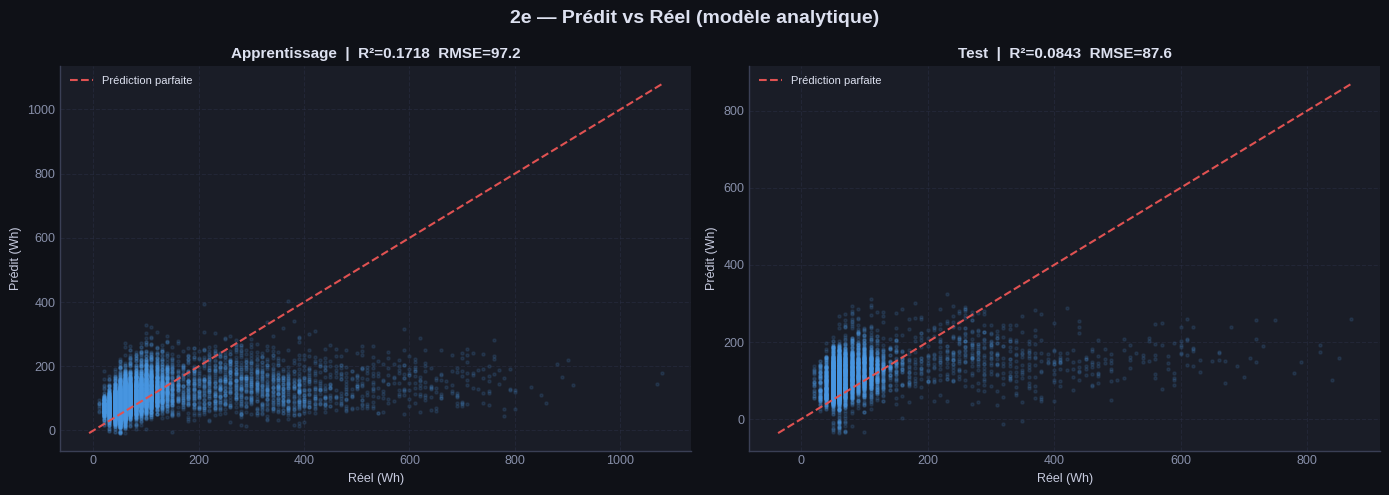

In [ ]:
y_train_pred_gd = X_train_b @ theta_gd
y_test_pred_gd  = X_test_b  @ theta_gd
y_train_pred_an = X_train_b @ theta_an
y_test_pred_an  = X_test_b  @ theta_an

def compute_metrics(y_true, y_pred):
    mse  = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2   = 1 - ss_res / ss_tot
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

m_gd_train = compute_metrics(y_train, y_train_pred_gd)
m_gd_test  = compute_metrics(y_test,  y_test_pred_gd)
m_an_train = compute_metrics(y_train, y_train_pred_an)
m_an_test  = compute_metrics(y_test,  y_test_pred_an)

print("\n  [2e] Performances — Gradient Descent (θ_GD) :")
print(f"    Train → MSE={m_gd_train['MSE']:.1f}  RMSE={m_gd_train['RMSE']:.2f}  "
      f"MAE={m_gd_train['MAE']:.2f}  R²={m_gd_train['R2']:.4f}")
print(f"    Test  → MSE={m_gd_test['MSE']:.1f}  RMSE={m_gd_test['RMSE']:.2f}  "
      f"MAE={m_gd_test['MAE']:.2f}  R²={m_gd_test['R2']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor="#0f1117")
fig.suptitle("2e — Prédit vs Réel (modèle analytique)",
             fontweight="bold", color="#dde1f0")

for ax, y_pred, y_true, split_name in zip(
    axes,
    [y_train_pred_an, y_test_pred_an],
    [y_train, y_test],
    ["Apprentissage", "Test"]
):
    m = compute_metrics(y_true, y_pred)
    ax.scatter(y_true, y_pred, alpha=0.12, s=5, color=BLUE)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, color=RED, lw=1.5, linestyle="--",
            label="Prédiction parfaite")
    ax.set_xlabel("Réel (Wh)")
    ax.set_ylabel("Prédit (Wh)")
    ax.set_title(f"{split_name}  |  R²={m['R2']:.4f}  RMSE={m['RMSE']:.1f}")
    ax.legend()

plt.tight_layout()
plt.show()

Ridge Regression

In [ ]:
def ridge_analytical(X_b, y, lam):
    n = X_b.shape[1]
    I = np.eye(n)
    I[0, 0] = 0   # ne pas pénaliser le biais
    return np.linalg.inv(X_b.T @ X_b + lam * I) @ X_b.T @ y

lambdas_wide   = np.logspace(-3, 6, 200)
train_r2_ridge_w = []
test_r2_ridge_w  = []

for lam in lambdas_wide:
    th = ridge_analytical(X_train_b, y_train, lam)
    m_tr = compute_metrics(y_train, X_train_b @ th)
    m_te = compute_metrics(y_test,  X_test_b  @ th)
    train_r2_ridge_w.append(m_tr["R2"])
    test_r2_ridge_w.append(m_te["R2"])

train_r2_ridge_w = np.array(train_r2_ridge_w)
test_r2_ridge_w  = np.array(test_r2_ridge_w)

# Fine-grained search
rough_best   = lambdas_wide[np.argmax(test_r2_ridge_w)]
lambdas_fine = np.logspace(
    max(-3, np.log10(rough_best) - 2),
    min(6,  np.log10(rough_best) + 2), 200)
tr_fine, te_fine = [], []
for lam in lambdas_fine:
    th = ridge_analytical(X_train_b, y_train, lam)
    tr_fine.append(compute_metrics(y_train, X_train_b @ th)["R2"])
    te_fine.append(compute_metrics(y_test,  X_test_b  @ th)["R2"])

# Merge grids
lambdas        = np.concatenate([lambdas_wide, lambdas_fine])
train_r2_ridge = np.concatenate([train_r2_ridge_w, np.array(tr_fine)])
test_r2_ridge  = np.concatenate([test_r2_ridge_w,  np.array(te_fine)])
sort_o = np.argsort(lambdas)
lambdas, train_r2_ridge, test_r2_ridge = (
    lambdas[sort_o], train_r2_ridge[sort_o], test_r2_ridge[sort_o])

best_idx    = np.argmax(test_r2_ridge)
best_lambda = lambdas[best_idx]
best_test_r2  = test_r2_ridge[best_idx]
best_train_r2 = train_r2_ridge[best_idx]

print(f"\n  Meilleur λ     : {best_lambda:.4f}")
print(f"  Train R²       : {best_train_r2:.4f}")
print(f"  Test  R²       : {best_test_r2:.4f}")


  Meilleur λ     : 1382.6222
  Train R²       : 0.1533
  Test  R²       : 0.1029


Ridge visualization


  Meilleur λ     : 1351.1815
  Train R²       : 0.1536
  Test  R²       : 0.1029


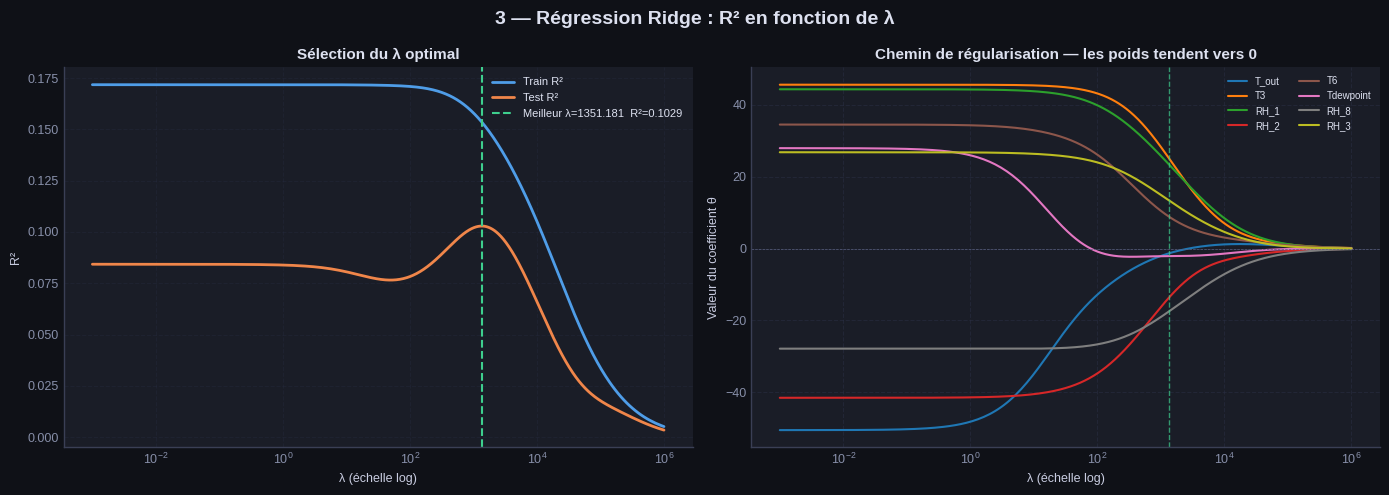

In [ ]:
def ridge_analytical(X_b, y, lam):
    n = X_b.shape[1]
    I = np.eye(n)
    I[0, 0] = 0   # ne pas pénaliser le biais
    return np.linalg.inv(X_b.T @ X_b + lam * I) @ X_b.T @ y

lambdas_wide   = np.logspace(-3, 6, 200)
train_r2_ridge_w = []
test_r2_ridge_w  = []

for lam in lambdas_wide:
    th = ridge_analytical(X_train_b, y_train, lam)
    m_tr = compute_metrics(y_train, X_train_b @ th)
    m_te = compute_metrics(y_test,  X_test_b  @ th)
    train_r2_ridge_w.append(m_tr["R2"])
    test_r2_ridge_w.append(m_te["R2"])

train_r2_ridge_w = np.array(train_r2_ridge_w)
test_r2_ridge_w  = np.array(test_r2_ridge_w)

# Fine-grained search around the best lambda
rough_best   = lambdas_wide[np.argmax(test_r2_ridge_w)]
lambdas_fine = np.logspace(
    max(-3, np.log10(rough_best) - 2),
    min(6,  np.log10(rough_best) + 2), 500)
tr_fine, te_fine = [], []
for lam in lambdas_fine:
    th = ridge_analytical(X_train_b, y_train, lam)
    tr_fine.append(compute_metrics(y_train, X_train_b @ th)["R2"])
    te_fine.append(compute_metrics(y_test,  X_test_b  @ th)["R2"])

# Merge wide + fine grids for the final curve
lambdas        = np.concatenate([lambdas_wide, lambdas_fine])
train_r2_ridge = np.concatenate([train_r2_ridge_w, np.array(tr_fine)])
test_r2_ridge  = np.concatenate([test_r2_ridge_w,  np.array(te_fine)])
sort_o = np.argsort(lambdas)
lambdas, train_r2_ridge, test_r2_ridge = (
    lambdas[sort_o], train_r2_ridge[sort_o], test_r2_ridge[sort_o])

best_idx    = np.argmax(test_r2_ridge)
best_lambda = lambdas[best_idx]
best_test_r2  = test_r2_ridge[best_idx]
best_train_r2 = train_r2_ridge[best_idx]

print(f"\n  Meilleur λ     : {best_lambda:.4f}")
print(f"  Train R²       : {best_train_r2:.4f}")
print(f"  Test  R²       : {best_test_r2:.4f}")

# VIZ : R² vs λ + regularisation path
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor="#0f1117")
fig.suptitle("3 — Régression Ridge : R² en fonction de λ",
             fontweight="bold", color="#dde1f0")

axes[0].semilogx(lambdas, train_r2_ridge, color=BLUE, lw=2,
                 label="Train R²")
axes[0].semilogx(lambdas, test_r2_ridge,  color=ORANGE, lw=2,
                 label="Test R²")
axes[0].axvline(best_lambda, color=GREEN, lw=1.5, linestyle="--",
                label=f"Meilleur λ={best_lambda:.3f}  R²={best_test_r2:.4f}")
axes[0].set_xlabel("λ (échelle log)")
axes[0].set_ylabel("R²")
axes[0].set_title("Sélection du λ optimal")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Chemin de régularisation — top 8 features
coef_matrix = []
for lam in lambdas:
    th = ridge_analytical(X_train_b, y_train, lam)
    coef_matrix.append(th[1:])
coef_matrix = np.array(coef_matrix)

top_idx  = np.argsort(np.abs(coef_matrix[0]))[::-1][:8]
cmap_reg = plt.cm.tab10
for rank, idx in enumerate(top_idx):
    axes[1].semilogx(lambdas, coef_matrix[:, idx],
                     color=cmap_reg(rank / 8), lw=1.5,
                     label=feature_names[idx])
axes[1].axhline(0, color=GREY, lw=0.5, linestyle="--")
axes[1].axvline(best_lambda, color=GREEN, lw=1, linestyle="--",
                alpha=0.7)
axes[1].set_xlabel("λ (échelle log)")
axes[1].set_ylabel("Valeur du coefficient θ")
axes[1].set_title("Chemin de régularisation — les poids tendent vers 0")
axes[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig("3_ridge.png", dpi=150, bbox_inches="tight",
            facecolor="#0f1117")
plt.show()

# Meilleur modèle Ridge
theta_ridge  = ridge_analytical(X_train_b, y_train, best_lambda)
y_tr_ridge   = X_train_b @ theta_ridge
y_te_ridge   = X_test_b  @ theta_ridge
m_ridge_train = compute_metrics(y_train, y_tr_ridge)
m_ridge_test  = compute_metrics(y_test,  y_te_ridge)

Feature importance

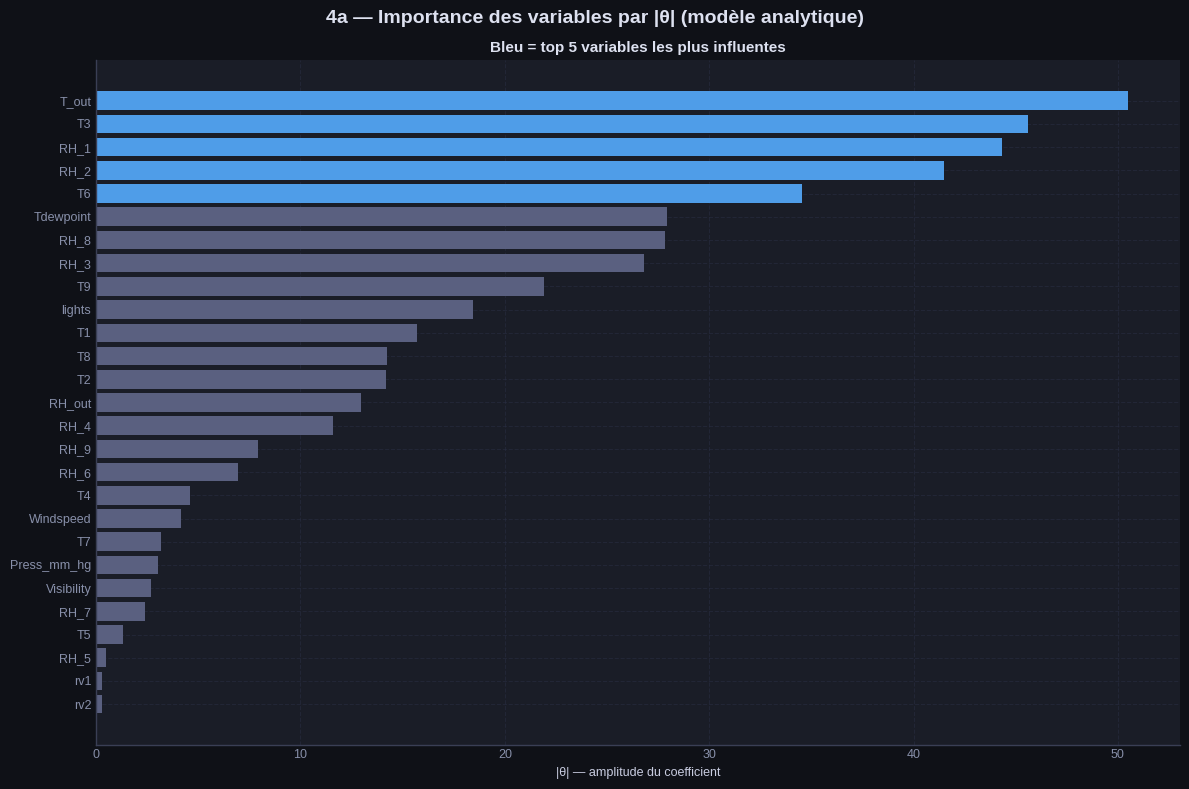


  Top 5 variables par |θ| :
    1. T_out                 |θ| = 50.5147
    2. T3                    |θ| = 45.6125
    3. RH_1                  |θ| = 44.3392
    4. RH_2                  |θ| = 41.5151
    5. T6                    |θ| = 34.5195


In [ ]:
abs_coef     = np.abs(theta_an[1:])
sorted_idx   = np.argsort(abs_coef)[::-1]
sorted_names = [feature_names[i] for i in sorted_idx]
sorted_coef  = abs_coef[sorted_idx]

bar_c = [BLUE if i < 5 else GREY for i in range(len(sorted_names))]

fig, ax = plt.subplots(figsize=(12, 8), facecolor="#0f1117")
fig.suptitle("4a — Importance des variables par |θ| (modèle analytique)",
             fontweight="bold", color="#dde1f0")
ax.barh(sorted_names[::-1], sorted_coef[::-1],
        color=bar_c[::-1], edgecolor="none")
ax.axvline(0, color=GREY, lw=0.5)
ax.set_xlabel("|θ| — amplitude du coefficient")
ax.set_title("Bleu = top 5 variables les plus influentes")
plt.tight_layout()
plt.show()

print("\n  Top 5 variables par |θ| :")
for i in range(5):
    print(f"    {i+1}. {sorted_names[i]:<20}  |θ| = {sorted_coef[i]:.4f}")

Subset selection - Top 5 by coefficient

In [ ]:
top5_names = sorted_names[:5]
print(f"\n  Top 5 sélectionnées (|θ|) : {top5_names}")

X5_train_raw = df_num[top5_names].values[:n_train]
X5_test_raw  = df_num[top5_names].values[n_train:]
mean5 = X5_train_raw.mean(axis=0)
std5  = X5_train_raw.std(axis=0); std5[std5 == 0] = 1
X5_train = (X5_train_raw - mean5) / std5
X5_test  = (X5_test_raw  - mean5) / std5

X5_train_b = np.c_[np.ones(len(X5_train)), X5_train]
X5_test_b  = np.c_[np.ones(len(X5_test)),  X5_test]

theta_5   = np.linalg.pinv(X5_train_b.T @ X5_train_b) @ X5_train_b.T @ y_train
m_5_test  = compute_metrics(y_test,  X5_test_b  @ theta_5)

print(f"\n  Modèle top-5 |θ| — Test R²={m_5_test['R2']:.4f}")


  Top 5 sélectionnées (|θ|) : ['T_out', 'T3', 'RH_1', 'RH_2', 'T6']

  Modèle top-5 |θ| — Test R²=-0.2768


 Subset selection - Top 10 by correlation

In [ ]:
top10_corr_names = corr_target.abs().sort_values(ascending=False).head(10).index.tolist()
print(f"\n  Top 10 par |corrélation| :")
for feat in top10_corr_names:
    r = corr_target[feat]
    print(f"    {feat:<20}  r = {r:+.3f}")

Xc_train_raw = df_num[top10_corr_names].values[:n_train]
Xc_test_raw  = df_num[top10_corr_names].values[n_train:]
meanc = Xc_train_raw.mean(axis=0)
stdc  = Xc_train_raw.std(axis=0); stdc[stdc == 0] = 1
Xc_train = (Xc_train_raw - meanc) / stdc
Xc_test  = (Xc_test_raw  - meanc) / stdc
Xc_train_b = np.c_[np.ones(len(Xc_train)), Xc_train]
Xc_test_b  = np.c_[np.ones(len(Xc_test)),  Xc_test]
theta_c   = np.linalg.pinv(Xc_train_b.T @ Xc_train_b) @ Xc_train_b.T @ y_train
m_c_test  = compute_metrics(y_test,  Xc_test_b  @ theta_c)

print(f"\n  Modèle top-10 corr — Test R²={m_c_test['R2']:.4f}")


  Top 10 par |corrélation| :
    lights                r = +0.197
    RH_out                r = -0.152
    T2                    r = +0.120
    T6                    r = +0.118
    T_out                 r = +0.099
    RH_8                  r = -0.094
    Windspeed             r = +0.087
    RH_1                  r = +0.086
    T3                    r = +0.085
    RH_6                  r = -0.083

  Modèle top-10 corr — Test R²=0.0753


3D Visualization


  Top 10 par |corrélation| (sélection robuste) :
    lights                r = +0.197
    RH_out                r = -0.152
    T2                    r = +0.120
    T6                    r = +0.118
    T_out                 r = +0.099
    RH_8                  r = -0.094
    Windspeed             r = +0.087
    RH_1                  r = +0.086
    T3                    r = +0.085
    RH_6                  r = -0.083

  Modèle top-10 corr — Train R²=0.1280  Test R²=0.0753
  → Avec 10 variables corrélées : sous-ensemble stable et interprétable.

  Top 2 variables pour visualisation 3D (par corrélation) : ['lights', 'RH_out']


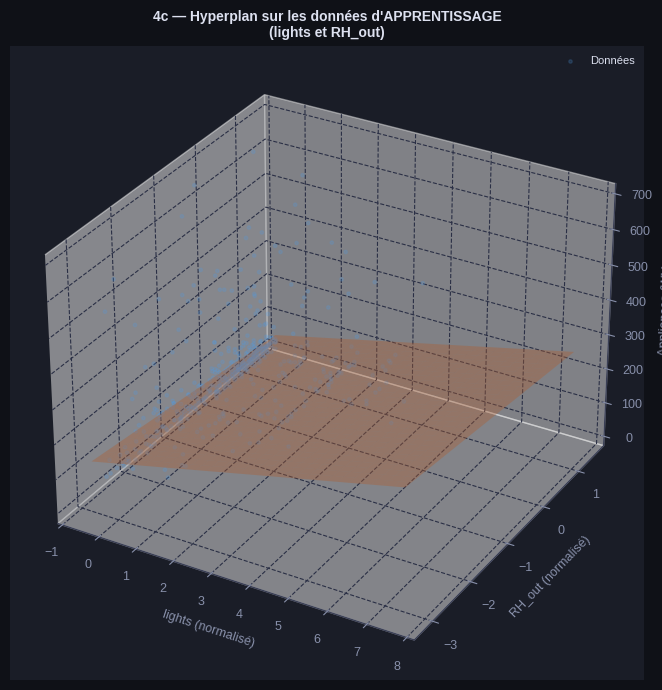

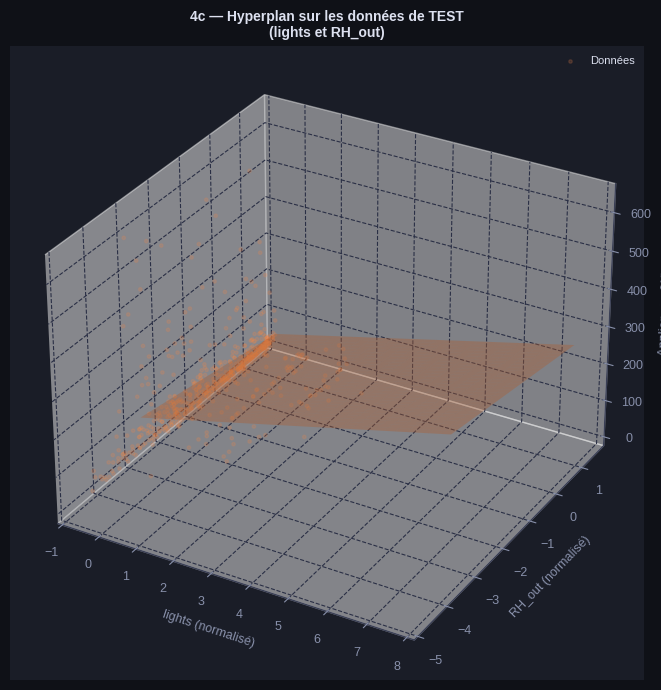

In [ ]:
# Top 10 features by correlation (robust to multicollinearity)
top5_corr_names = corr_target.abs().sort_values(ascending=False).head(10).index.tolist()
print(f"\n  Top 10 par |corrélation| (sélection robuste) :")
for feat in top5_corr_names:
    r = corr_target[feat]
    print(f"    {feat:<20}  r = {r:+.3f}")

# Build and evaluate model with 10 correlation‑selected features
Xc_train_raw = df_num[top5_corr_names].values[:n_train]
Xc_test_raw  = df_num[top5_corr_names].values[n_train:]
meanc = Xc_train_raw.mean(axis=0)
stdc  = Xc_train_raw.std(axis=0); stdc[stdc == 0] = 1
Xc_train = (Xc_train_raw - meanc) / stdc
Xc_test  = (Xc_test_raw  - meanc) / stdc
Xc_train_b = np.c_[np.ones(len(Xc_train)), Xc_train]
Xc_test_b  = np.c_[np.ones(len(Xc_test)),  Xc_test]
theta_c   = np.linalg.pinv(Xc_train_b.T @ Xc_train_b) @ Xc_train_b.T @ y_train
m_c_train = compute_metrics(y_train, Xc_train_b @ theta_c)
m_c_test  = compute_metrics(y_test,  Xc_test_b  @ theta_c)

print(f"\n  Modèle top-10 corr — Train R²={m_c_train['R2']:.4f}  Test R²={m_c_test['R2']:.4f}")
print("  → Avec 10 variables corrélées : sous-ensemble stable et interprétable.")

# 3D plot using the two most correlated features (not the ones with largest |θ|)
top2 = top5_corr_names[:2]
print(f"\n  Top 2 variables pour visualisation 3D (par corrélation) : {top2}")

mean2 = df_num[top2].values[:n_train].mean(axis=0)
std2  = df_num[top2].values[:n_train].std(axis=0)
std2[std2 == 0] = 1

X2_train = (df_num[top2].values[:n_train] - mean2) / std2
X2_test  = (df_num[top2].values[n_train:] - mean2) / std2
X2_train_b = np.c_[np.ones(len(X2_train)), X2_train]
X2_test_b  = np.c_[np.ones(len(X2_test)),  X2_test]

theta_2 = np.linalg.pinv(X2_train_b.T @ X2_train_b) @ X2_train_b.T @ y_train

x1r = np.linspace(X2_train[:, 0].min(), X2_train[:, 0].max(), 30)
x2r = np.linspace(X2_train[:, 1].min(), X2_train[:, 1].max(), 30)
xx1, xx2 = np.meshgrid(x1r, x2r)
zz = theta_2[0] + theta_2[1] * xx1 + theta_2[2] * xx2

def plot_3d_hyperplane(X2, y_true, title, fname, pt_color):
    step = max(1, len(X2) // 600)
    fig  = plt.figure(figsize=(10, 7), facecolor="#0f1117")
    ax   = fig.add_subplot(111, projection="3d")
    ax.set_facecolor("#1a1d27")
    ax.scatter(X2[::step, 0], X2[::step, 1], y_true[::step],
               alpha=0.18, s=6, color=pt_color, label="Données")
    surf = ax.plot_surface(xx1, xx2, zz, alpha=0.4,
                           color=ORANGE, edgecolor="none")
    ax.set_xlabel(f"{top2[0]} (normalisé)", color="#8890aa")
    ax.set_ylabel(f"{top2[1]} (normalisé)", color="#8890aa")
    ax.set_zlabel("Appliances (Wh)", color="#8890aa")
    ax.set_title(title, color="#dde1f0", fontsize=10)
    ax.tick_params(colors="#8890aa")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight", facecolor="#0f1117")
    plt.show()

plot_3d_hyperplane(X2_train, y_train,
                   f"4c — Hyperplan sur les données d'APPRENTISSAGE\n({top2[0]} et {top2[1]})",
                   "4c_3d_train.png", BLUE)

plot_3d_hyperplane(X2_test, y_test,
                   f"4c — Hyperplan sur les données de TEST\n({top2[0]} et {top2[1]})",
                   "4c_3d_test.png", ORANGE)

Final comparison table


  SECTION 5 — ÉVALUATION DES PERFORMANCES

  Modèle                                      Train MSE Train RMSE Train MAE Train R²    Test MSE  Test RMSE  Test MAE  Test R²
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  OLS — Analytique = référence exacte            9455.9      97.24     55.57   0.1718      7679.3      87.63     56.08   0.0843
  OLS — GD α=0.01 convergé                       9478.3      97.36     55.57   0.1699      7774.9      88.18     56.33   0.0729
  Ridge (λ=1351.181)                             9663.6      98.30     55.95   0.1536      7523.2      86.74     53.38   0.1029
  Top-5 |θ| (T_out, T3…) [collin.]              10516.7     102.55     60.36   0.0789     10707.5     103.48     79.70  -0.2768
  Top-10 corr (lights…)                          9956.4      99.78     57.29   0.1280      7754.3      88.06     52.95   0.0753


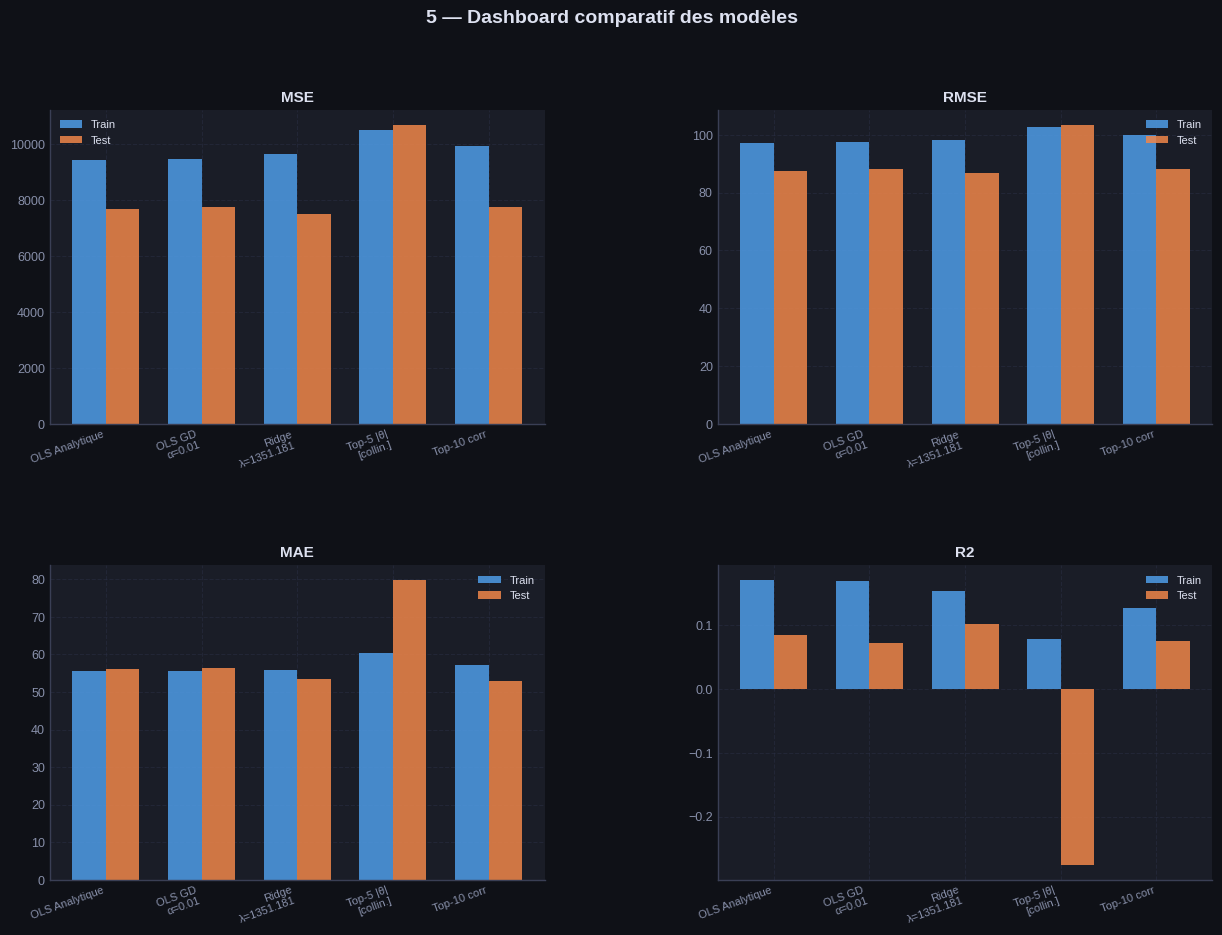


  RÉSUMÉ & CONCLUSIONS

  Meilleur modèle (Test R²) : Ridge (λ=1351.181)
    MSE  = 7523.16
    RMSE = 86.74 Wh
    MAE  = 53.38 Wh
    R²   = 0.1029


In [ ]:

# ─────────────────────────────────────────────────────────────
# SECTION 5 — TABLEAU COMPARATIF COMPLET
# ─────────────────────────────────────────────────────────────
import matplotlib.gridspec as gridspec
print("\n" + "="*60)
print("  SECTION 5 — ÉVALUATION DES PERFORMANCES")
print("="*60)

models = [
    ("OLS — Analytique = référence exacte",    compute_metrics(y_train, y_train_pred_an),  compute_metrics(y_test, y_test_pred_an)),
    ("OLS — GD α=0.01 convergé",               compute_metrics(y_train, y_train_pred_gd),  compute_metrics(y_test, y_test_pred_gd)),
    (f"Ridge (λ={best_lambda:.3f})",           m_ridge_train,                              m_ridge_test),
    (f"Top-5 |θ| ({', '.join(top5_names[:2])}…) [collin.]", m_5_train,                   m_5_test),
    (f"Top-10 corr ({top5_corr_names[0]}…)",   m_c_train,                                  m_c_test),
]

header = f"  {'Modèle':<42} {'Train MSE':>10} {'Train RMSE':>10} {'Train MAE':>9} {'Train R²':>8}  {'Test MSE':>10} {'Test RMSE':>10} {'Test MAE':>9} {'Test R²':>8}"
print("\n" + header)
print("  " + "─" * 130)

for name, m_tr, m_te in models:
    print(f"  {name:<42} "
          f"{m_tr['MSE']:>10.1f} {m_tr['RMSE']:>10.2f} {m_tr['MAE']:>9.2f} {m_tr['R2']:>8.4f}  "
          f"{m_te['MSE']:>10.1f} {m_te['RMSE']:>10.2f} {m_te['MAE']:>9.2f} {m_te['R2']:>8.4f}")

# ── VIZ 5 : Dashboard comparatif ──
fig = plt.figure(figsize=(15, 10), facecolor="#0f1117")
fig.suptitle("5 — Dashboard comparatif des modèles",
             fontweight="bold", color="#dde1f0", fontsize=14)

model_labels = ["OLS Analytique", f"OLS GD\nα=0.01", f"Ridge\nλ={best_lambda:.3f}",
                "Top-5 |θ|\n[collin.]", "Top-10 corr"]
metrics_names = ["MSE", "RMSE", "MAE", "R2"]
train_vals = [[m_tr[k] for k in metrics_names] for _, m_tr, _ in models]
test_vals  = [[m_te[k] for k in metrics_names] for _, _, m_te in models]

gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
axes5 = [fig.add_subplot(gs[i//2, i%2]) for i in range(4)]

for ax_i, metric in enumerate(metrics_names):
    ax  = axes5[ax_i]
    x   = np.arange(len(model_labels))
    w   = 0.35
    t_v = [tv[ax_i] for tv in train_vals]
    e_v = [ev[ax_i] for ev in test_vals]
    ax.bar(x - w/2, t_v, width=w, color=BLUE,   alpha=0.85, label="Train")
    ax.bar(x + w/2, e_v, width=w, color=ORANGE, alpha=0.85, label="Test")
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=20, ha="right", fontsize=8)
    ax.set_title(metric)
    ax.legend(fontsize=8)

plt.savefig("5_comparaison.png", dpi=150, bbox_inches="tight",
            facecolor="#0f1117")
plt.show()
# ─────────────────────────────────────────────────────────────
# RÉSUMÉ FINAL
# ─────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("  RÉSUMÉ & CONCLUSIONS")
print("="*60)

best_model_idx = np.argmax([m_te["R2"] for _, _, m_te in models])
best_name, _, best_m_te = models[best_model_idx]

print(f"\n  Meilleur modèle (Test R²) : {best_name}")
print(f"    MSE  = {best_m_te['MSE']:.2f}")
print(f"    RMSE = {best_m_te['RMSE']:.2f} Wh")
print(f"    MAE  = {best_m_te['MAE']:.2f} Wh")
print(f"    R²   = {best_m_te['R2']:.4f}")




  OBSERVATIONS (résultats réels de ce run) :
  • R² test ≈ 0.08–0.10 : le modèle linéaire n'explique que ~10% de la variance.
    
    → La consommation électrique est fortement non-linéaire et bruitée.

  • GD (α=0.01, 3000 iter) : convergence stable et régulière vers une solution proche de la référence analytique.
α=0.01 est choisi comme meilleur compromis vitesse/robustesse.

  • Ridge (λ≈1351) donne le meilleur test R²=0.1029 en stabilisant les
  coefficients instables dus à la multicolinéarité. C'est l'apport clé de Ridge.

  • rv1 et rv2 (variables de bruit aléatoire) ont |θ|≈0.28 → ignorées par le modèle. Bonne validation : le modèle ne sur-apprend pas le bruit.